# 1. Problem

Recover a complete-plane nonnegative T2 bin-mass distribution and conditional myelin water fraction from real ex vivo MESE observations. The 32 echoes include stimulated echoes from nonideal refocusing. There are 100 unknown masses per pixel, so the selected standard uses nonnegative ridge estimation.

This is the conventional MESE comparator in Nataraj et al., *Fast, Precise Myelin Water Quantification using DESS MRI and Kernel Learning*, arXiv:1809.08908v1, Supplement S-I.B. It is not the paper's DESS/PERK training branch. The source RF-axis bug was independently identified and corrected in V2. Original V1 NNLS/RNNLS are retained as explicit incorrect-phase counterfactuals. No independent T2 or MWF truth is available; source reconstruction is a method reference.

In [1]:
from pathlib import Path
import sys,os,time,json,subprocess
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
get_ipython().run_line_magic('matplotlib','inline')
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/main.py').exists() and (p/'data/raw_data.npz').exists())
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,T2_MS,LAMBDA
from src.main import reconstruct
from src.solvers import objective_and_gap
from src.visualization import make_figures
data=load_data(ROOT/'data/raw_data.npz')
print('Python',sys.version.split()[0],'NumPy',np.__version__,'platform',sys.platform)
print('Complete plane',data['observed'].shape,'fit pixels',data['mask'].sum(),'display pixels',data['display_mask'].sum())

Python 3.11.11 NumPy 2.4.6 platform win32
Complete plane (120, 120, 32) fit pixels 2629 display pixels 1752


# 2. Data

All four original float64 magnitude repetitions are averaged for inversion. The original complex first-echo repetitions establish the foreground independently of fitting. The frozen display mask comes from thresholding, hole filling and exact radius-5 disk **opening**; the fitting mask is its radius-5 dilation. The display mask has 1752 pixels and the full fitting mask has 2629. Halo pixels remain in every objective and diagnostic.

Independent SPGR T1 and Bloch-Siegert transmit maps determine the source's unstandardized 100-cluster calibration. Labels and centers are supplied as fixed approximate calibration, with the original maps still visible. The approximation is substantial at some pixels; it must not be described as exact B1 calibration. Array coordinates are unchanged row,column pixels; all 120 by 120 images and 32 echoes are retained.

In [2]:
mask=data['mask'];display_mask=data['display_mask']
kap_error=np.abs(data['flip_scale'][mask]-data['cluster_centroids'][data['labels'],1])
display_in_fit=display_mask[mask]
display(Markdown('| Calibration discrepancy | Median | Maximum | Unit |\n|---|---:|---:|---|\n'+f'| Absolute kappa cluster error, all fit pixels | {np.median(kap_error):.8g} | {kap_error.max():.8g} | dimensionless |\n'+f'| Absolute kappa cluster error, display pixels | {np.median(kap_error[display_in_fit]):.8g} | {kap_error[display_in_fit].max():.8g} | dimensionless |'))
print('Actual independent-map range on fit mask: T1/ms',data['t1_ms'][mask].min(),data['t1_ms'][mask].max(),'kappa',data['flip_scale'][mask].min(),data['flip_scale'][mask].max())

| Calibration discrepancy | Median | Maximum | Unit |
|---|---:|---:|---|
| Absolute kappa cluster error, all fit pixels | 0.052392285 | 1.6641495 | dimensionless |
| Absolute kappa cluster error, display pixels | 0.033204329 | 1.0951761 | dimensionless |

Actual independent-map range on fit mask: T1/ms 100.0 3000.000000000001 kappa 0.48358378 3.0085254


# 3. Physics

For each bin coordinate t (T2 in ms), unit-density initial longitudinal magnetization is 1-exp(-TR/T1). Fourier states F+=Mx+iMy, F-=Mx-iMy, Z=Mz occupy orders -128 through 128. RF pulses rotate the physical vector by a right-handed Rodrigues matrix about the axis n=(cos(phi),sin(phi),0), with angle alpha=kappa times nominal flip:

$$R=\cos(\alpha)I+[1-\cos(\alpha)]nn^{\mathsf T}+\sin(\alpha)[n]_{\times}.$$

I is the identity and the cross-product matrix acts as [n]cross*v=n cross v. RF axis phase phi remains fixed independently of amplitude kappa. Excitation is (pi/2,0); every refocusing pulse is (pi,pi/2), in radians. In each 4.6 ms half interval, transverse states decay by exp(-4.6/t) and longitudinal states by exp(-4.6/T1), with recovery into Z0 only. Crusher lobes shift F+ by +2 and F- by -2 Fourier orders. Each of 32 echoes contains two half intervals, two crushers and one refocusing pulse. TR=1000 ms and TE=9.2 ms.

The dictionary A(e,j) is the magnitude of the unit-density zero-order transverse signal at echo e for bin j. Its amplitude-mixture prediction is

$$y_e=\sum_{j=0}^{99}A_{ej}x_j+\epsilon_e.$$

Here y is the mean measured curve in AU, x is nonnegative mass in AU, and epsilon includes noise and model mismatch. Bins are logarithmic from 10 to 3000 ms; masses are not densities and do not carry bin-width factors. Exchange, diffusion, intrapulse effects and pre-excitation transverse states are omitted. The source initialization approximates recovery rather than a full periodic steady state.

V1 incorrectly multiplied RF phase by kappa. V2 only removes that factor while preserving flip scaling. Independent physical Bloch/Rodrigues simulation of 1024 isochromats over 21 parameter cases and all echoes agrees with V2 to 5.6e-16; V1 has maximum magnitude discrepancy 0.0960 in those controls. The full V1 runs below remain clearly labeled.

# 4. Method

The standard uses the following strongly convex objective at every fitting pixel:

$$J(x)=\|Ax-y\|_2^2+\lambda\|x\|_2^2,\qquad x\geq0.$$

The fixed dimensionless lambda is 0.003719667767540722 in the original AU coordinates. The source multiplies the paper's nominal 2^-13 by the squared first-echo median 5.5201012990427625 AU, using estimation pixels strictly above 5% of the global first-echo maximum. This extra source scaling is preserved and disclosed. There is no factor of one-half, echo average, per-pixel normalization or column normalization.

The local solver starts from zero, admits the inactive coordinate with greatest improving dual gradient, solves its passive linear system, and takes a feasible line step if a passive solution becomes negative. It removes coordinates hitting zero and stops at the explicit dual-gradient tolerance. The unregularized comparison uses the same active-set logic with general restricted least squares. Neither branch calls an upstream domain package.

Evaluation checks the source-quality ceiling and a per-pixel primal-dual gap. With u=Ax-y and g=A-transpose*u, the stable gap is

$$G=\|\sqrt{\lambda}x+\min(g,0)/\sqrt{\lambda}\|_2^2+2x^{\mathsf T}\max(g,0).$$

The global sum of J must be <=118.3373325908039 AU squared, and max G/max(J,1e-6) must be <=1e-6 over all fitting pixels. Total density, myelin fraction, full curves and zero-outside-mask behavior are independently checked. This one-part-per-million optimization tolerance says nothing about true tissue-parameter accuracy.

The next cell actively performs **both complete inversions**. Source measurements are loaded separately afterwards; none is substituted for a fresh result.

In [3]:
start=time.perf_counter();fresh_ridge,aux=reconstruct(ROOT/'data/raw_data.npz');ridge_seconds=time.perf_counter()-start
start=time.perf_counter();fresh_nnls,aux_nnls=reconstruct(ROOT/'data/raw_data.npz',ridge=0.);nnls_seconds=time.perf_counter()-start
np.savez_compressed(ROOT/'output/reconstruction.npz',**fresh_ridge)
J,gap=objective_and_gap(aux['dictionary'],aux['coefficients'],data['y'],data['labels'],LAMBDA)
print('Fresh complete RNNLS seconds:',ridge_seconds,'NNLS seconds:',nnls_seconds)
print('Fresh objective:',J.sum(),'max relative duality gap:',np.max(gap/np.maximum(J,1e-6)))
judge=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
assert judge.returncode==0,(judge.stdout,judge.stderr)
report=json.loads((ROOT/'output/judge_report.json').read_text())
display(Markdown('| Judge metric | Fresh value | Boundary |\n|---|---:|---:|\n'+'\n'.join(f"| {k} | {v:.12g} | {report['thresholds'][k]['boundary']:.12g} |" for k,v in report['metrics'].items())))

Fresh complete RNNLS seconds: 6.75779419997707 NNLS seconds: 6.809274800005369
Fresh objective: 118.33721425358965 max relative duality gap: 6.464384839566843e-23


| Judge metric | Fresh value | Boundary |
|---|---:|---:|
| total_density_consistency | 0 | 1e-08 |
| myelin_fraction_consistency | 0 | 1e-08 |
| predicted_echoes_consistency | 4.11868070955e-16 | 1e-08 |
| outside_mask_max | 0 | 1e-08 |
| objective_sum | 118.337214254 | 118.337332591 |
| scaled_duality_gap | 6.47966882784e-23 | 1e-06 |

# 5. Results

Source entries below are complete runs on these exact observations: V1 NNLS was serial (1187.024 s), and the remaining branches ran all 100 independent calibration clusters with four native Octave 8.4.0 processes (V1 ridge 383.599 s, V2 NNLS 298.924 s, V2 ridge 314.169 s). Those times are provenance, not a controlled MATLAB-versus-Python speed benchmark; V1 ridge includes a short resource pause. Fresh timings above come from this notebook's two complete local computations.

There is no ground truth. V1 and V2 residuals are evaluated with their own explicitly identified forward conventions; a lower wrong-model residual cannot validate RF physics. All six groups remain in the fraction maps, spatially fixed pixel curves, mass spectra and regional comparisons. The same fixed full fitting mask is used everywhere.

| Method / provenance | Full data SSE / AU squared | Objective / AU squared | Display mean MWF | Wall seconds |
|---|---:|---:|---:|---:|
| V1 NNLS source | 86.4513739 | 86.4513739 | 0.2869617 | 1187 |
| V1 ridge source | 91.1841908 | 113.637781 | 0.3633547 | 383.6 |
| V2 NNLS source | 91.7324754 | 91.7324754 | 0.3002017 | 298.92 |
| V2 ridge source | 96.2640664 | 118.337214 | 0.3673953 | 314.17 |
| V2 NNLS fresh | 91.7324754 | 91.7324754 | 0.3002017 | 6.8093 |
| V2 ridge fresh | 96.2640664 | 118.337214 | 0.3673953 | 6.7578 |

Fresh versus independently executed V2 ridge maximum mass difference / AU: 3.3300064095076465e-12


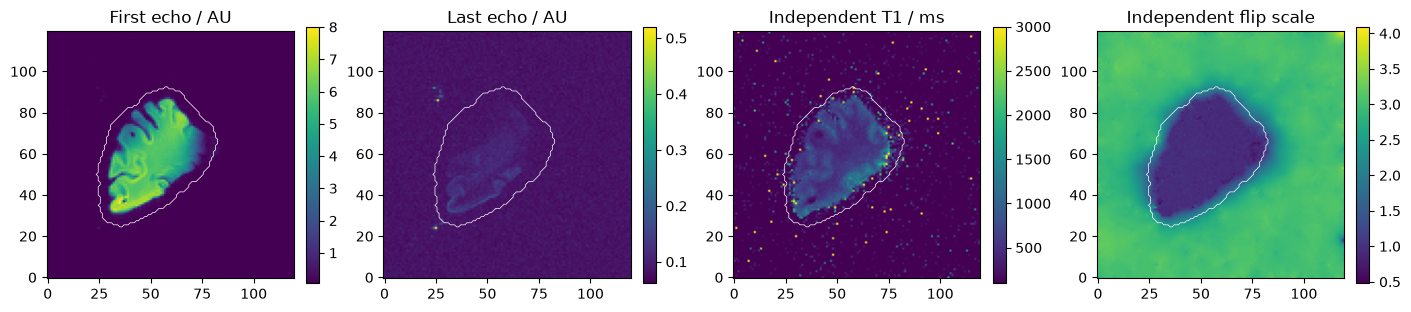

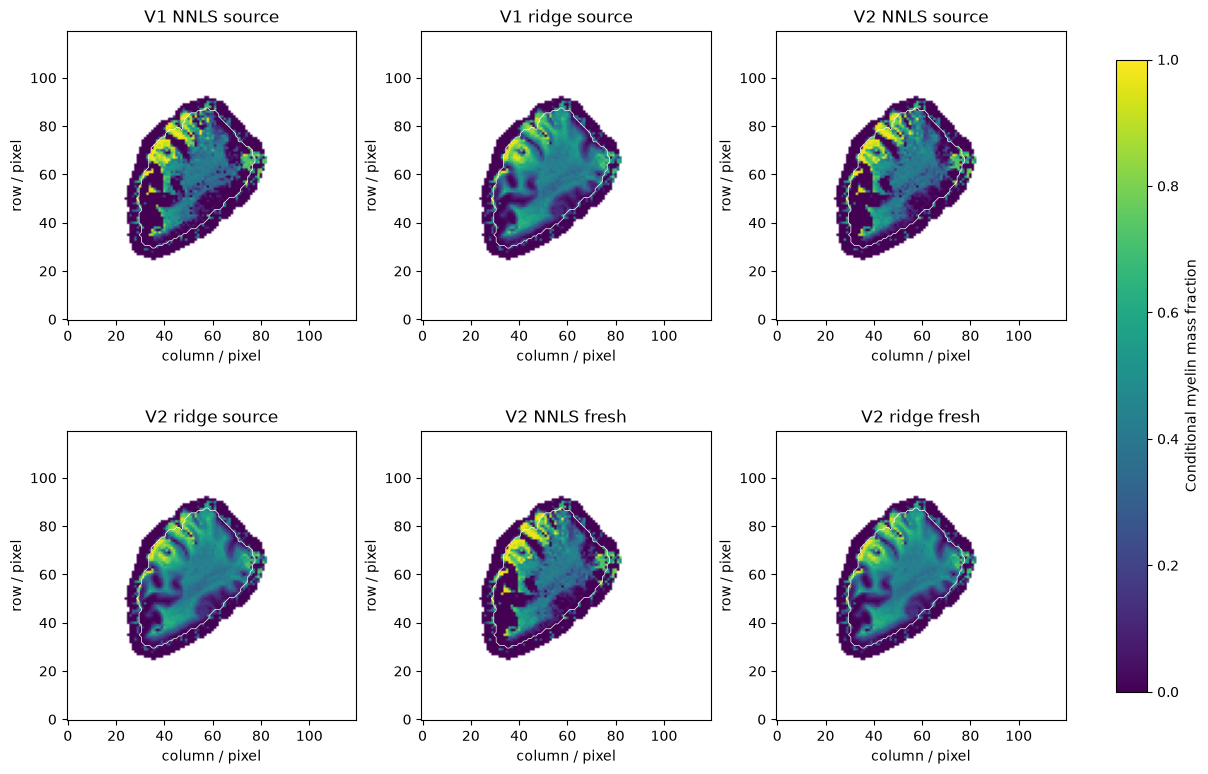

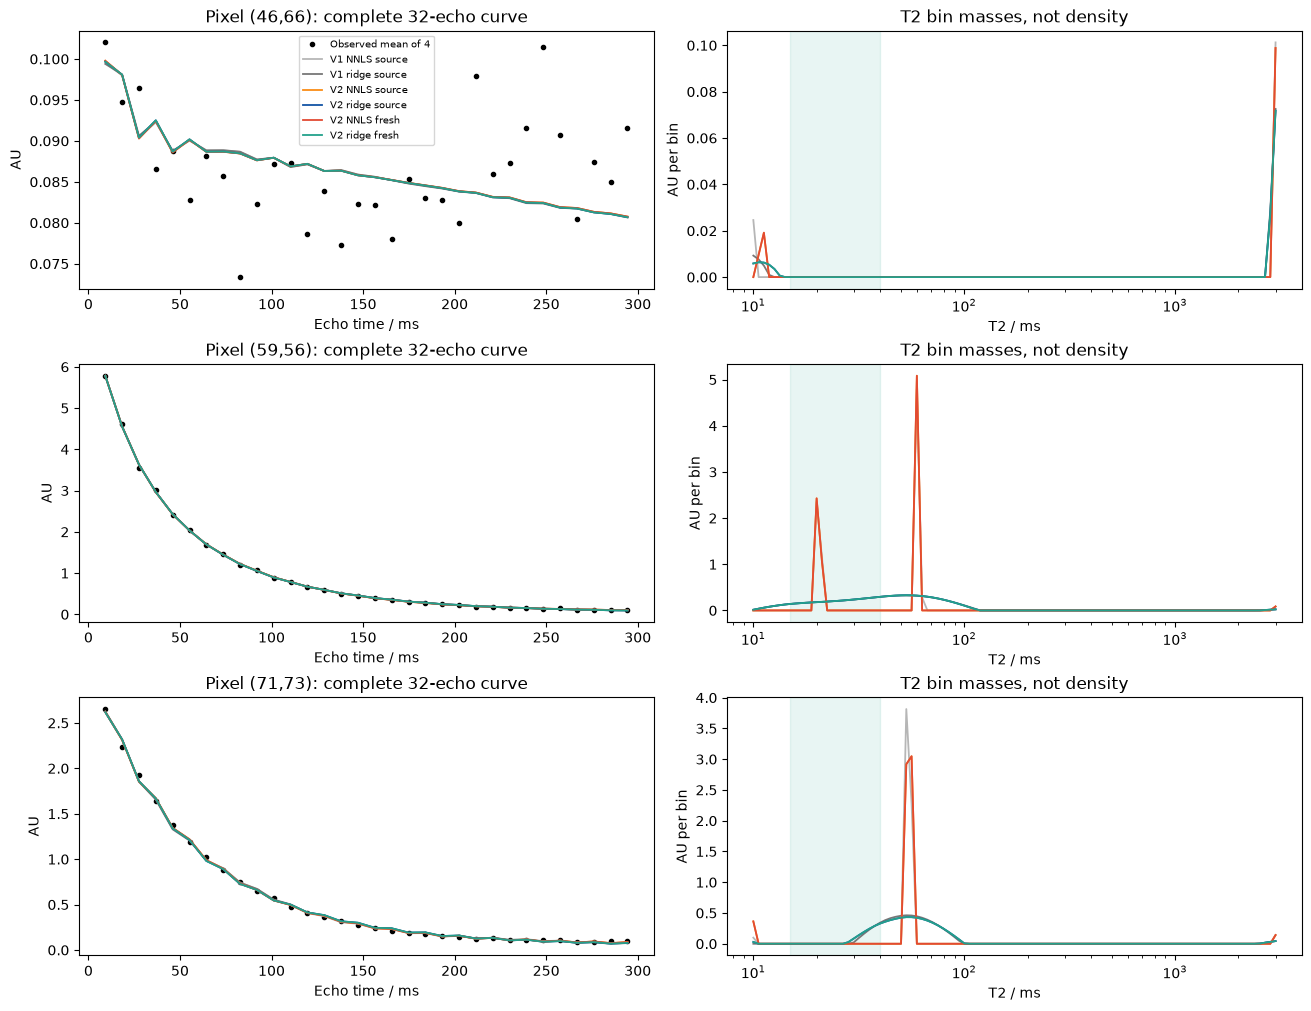

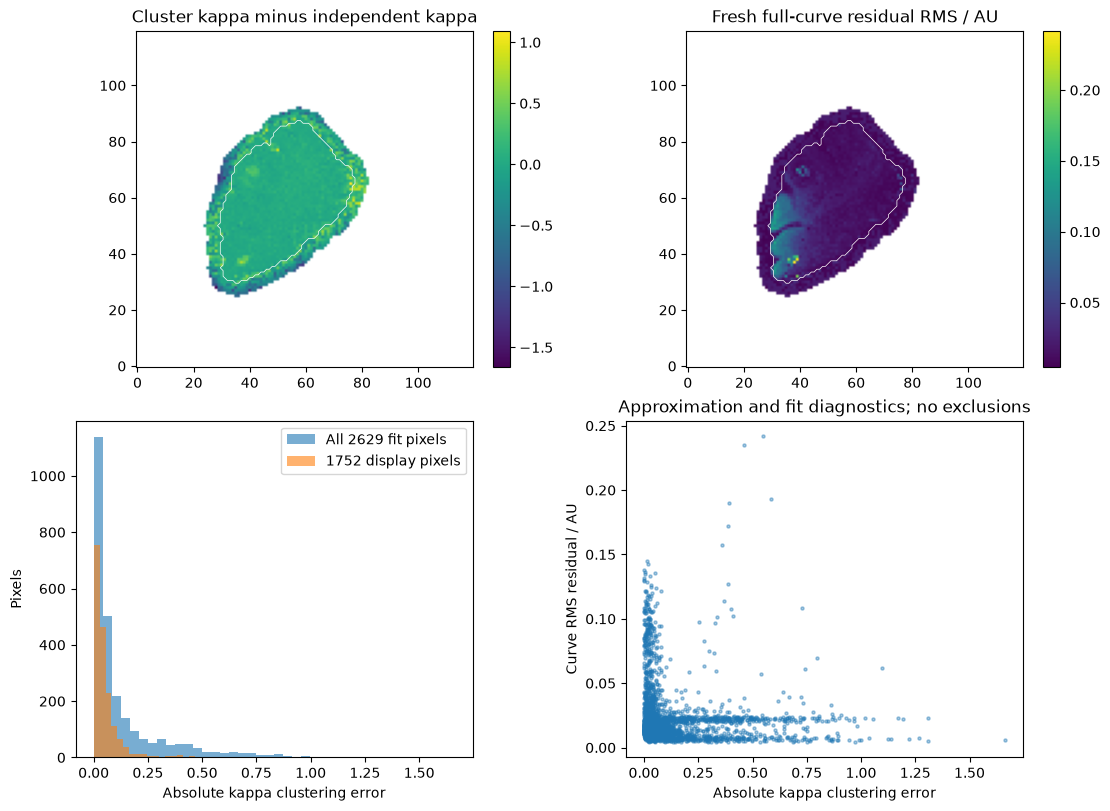

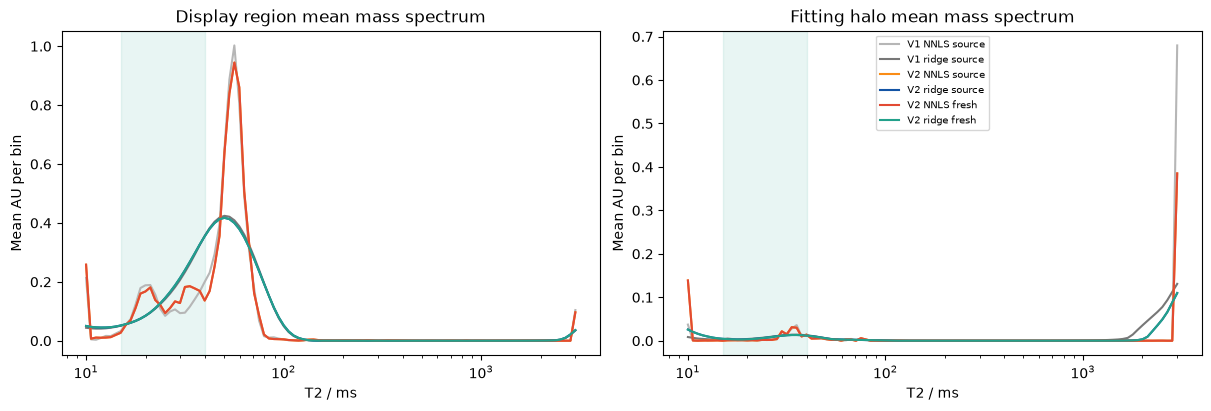

In [4]:
def load_result(path):
    with np.load(path,allow_pickle=False) as z:return {k:z[k] for k in z.files}
results={
 'V1 NNLS source':load_result(ROOT/'notebooks/reference_outputs/upstream_v1_mode0.npz'),
 'V1 ridge source':load_result(ROOT/'notebooks/reference_outputs/upstream_v1_mode1.npz'),
 'V2 NNLS source':load_result(ROOT/'notebooks/reference_outputs/upstream_v2_mode0.npz'),
 'V2 ridge source':load_result(ROOT/'evaluation/baseline_reference.npz'),
 'V2 NNLS fresh':fresh_nnls,
 'V2 ridge fresh':fresh_ridge}
times=[1187.024,383.59877943992615,298.9244215488434,314.1691093444824,nnls_seconds,ridge_seconds]
rows=[]
for (name,r),seconds in zip(results.items(),times):
    x=r['reconstruction'][0][mask];u=r['predicted_echoes'][0][mask]-data['y'];sse=np.sum(u*u);lam=0. if 'NNLS' in name else LAMBDA;objective=sse+lam*np.sum(x*x)
    rows.append(f"| {name} | {sse:.9g} | {objective:.9g} | {r['myelin_fraction'][0][display_mask].mean():.7g} | {seconds:.5g} |")
display(Markdown('| Method / provenance | Full data SSE / AU squared | Objective / AU squared | Display mean MWF | Wall seconds |\n|---|---:|---:|---:|---:|\n'+'\n'.join(rows)))
print('Fresh versus independently executed V2 ridge maximum mass difference / AU:',np.max(abs(fresh_ridge['reconstruction']-results['V2 ridge source']['reconstruction'])))
figures=make_figures(data,results)
review=Path(os.environ['IMAGING101_REVIEW_DIR']) if os.environ.get('IMAGING101_REVIEW_DIR') else None
for i,fig in enumerate(figures,1):
    if review is not None:
        review.mkdir(parents=True,exist_ok=True);fig.savefig(review/f'mwf_figure_{i}.png',dpi=130)
    display(fig);plt.close(fig)

# 6. Conclusion

The fresh full-plane implementation matches the independently run corrected source and passes the implementation-independent optimization and output checks. Regularization changes the mass distribution and derived myelin fraction substantially in some regions; that reflects an ill-conditioned multi-component inverse problem, rather than a measured change in tissue.

All 2629 fitting pixels, including the halo and extreme independent-calibration values, remain present. The white display contour never changes metric support. The calibration-error plots expose the coarse unstandardized clustering, whose maximum absolute kappa error is 1.664 on the fitting mask. Further limitations include the approximate recovery model, magnitude-mixture assumptions, omitted exchange and other dynamics, finite echo sampling, and formalin-fixed ex vivo tissue. No histological or independently measured T2/MWF truth is available. The reported certificate establishes numerical optimization quality under the declared conditional model; it does not establish physiological accuracy.